In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

Part A— Tabular Q-learning in a 4×4 GridWorld.
- Use a 4 × 4 grid: start top-left, goal bottom-right, and a trap. Ordinary moves cost −0.04, the goal
pays +1, and the trap pays −1 and terminates.
- Walls leave position unchanged. step returns state,
reward, and termination.

In [23]:
rng = np.random.default_rng(42)
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [24]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS))) # explore: random move
    return int(np.argmax(Q[state]))            # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] = Q[state][action] + alpha * (target - Q[state][action])
        
        state = next_state
        if done:
            break
            
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

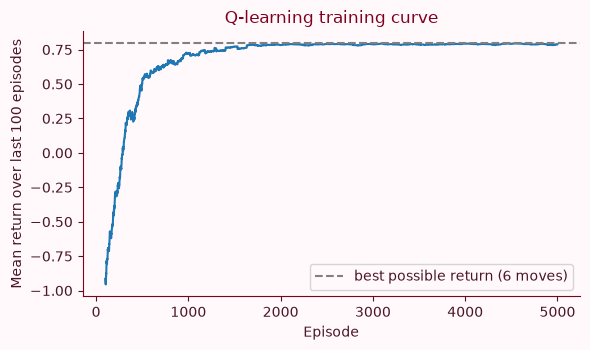

In [25]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


Part B — The Q-table is the model: save it and read the policy.

In [27]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)

for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
                       else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
        
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


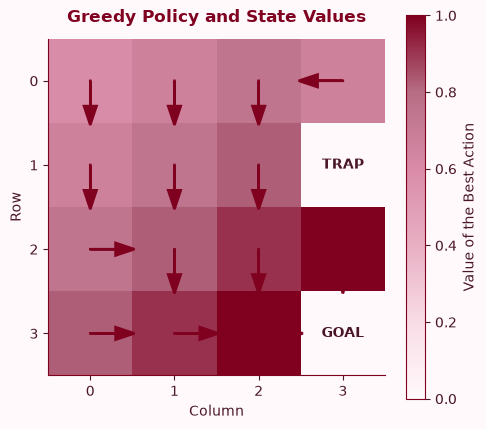

In [30]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)

    # Sakura Blossom + Burgundy colour palette
    from matplotlib.colors import LinearSegmentedColormap

    sakura_cmap = LinearSegmentedColormap.from_list(
        "SakuraBurgundy",
        [
            "#FFF9FB",  # Soft white pink
            "#F8DCE6",  # Sakura pink
            "#E8AFC3",  # Cherry blossom
            "#D98BA7",  # Dusty rose
            "#B76E85",  # Deep sakura
            "#800020"   # Burgundy
        ]
    )

    plt.figure(figsize=(5, 4.5))
    plt.imshow(values, cmap=sakura_cmap)

    plt.colorbar(label="Value of the Best Action")

    for r in range(ROWS):
        for c in range(COLS):

            if (r, c) == GOAL:
                plt.text(
                    c, r, "GOAL",
                    ha="center", va="center",
                    fontweight="bold",
                    color="#4A1728"
                )

            elif (r, c) == TRAP:
                plt.text(
                    c, r, "TRAP",
                    ha="center", va="center",
                    color="#4A1728",
                    fontweight="bold"
                )

            else:
                dx, dy = ARROWS[
                    ACTION_NAMES[int(np.argmax(Q_table[r, c]))]
                ]

                plt.arrow(
                    c, r,
                    0.3 * dx, -0.3 * dy,
                    head_width=0.15,
                    color="#800020",
                    linewidth=1.8
                )

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))

    plt.title(
        title,
        fontsize=12,
        fontweight="bold",
        color="#800020",
        pad=12
    )

    plt.xlabel("Column")
    plt.ylabel("Row")

    plt.tight_layout()
    plt.show()


plot_policy(Q_loaded, "Greedy Policy and State Values")

Try it yourself part

In [37]:
# 1. Redefine the step function with a high step cost (-0.5)

def step_high_cost(state, action):
    r, c = state
    dr, dc = ACTIONS[action]

    next_state = (
        min(max(r + dr, 0), ROWS - 1),
        min(max(c + dc, 0), COLS - 1)
    )

    if next_state == GOAL:
        return next_state, 1.0, True

    if next_state == TRAP:
        return next_state, -1.0, True

    return next_state, -0.5, False  # High step cost

In [38]:
# 2. Reset Q-table and exploration parameters

Q_new = np.zeros((ROWS, COLS, len(ACTIONS)))

alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action_new(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))

    return int(np.argmax(Q_new[state]))

In [39]:
# 3. Retrain the model using the new step function

training_returns_new = []

for episode in range(5000):
    state = START
    episode_return = 0.0

    for _ in range(100):
        action = choose_action_new(state)

        next_state, reward, done = step_high_cost(state, action)

        episode_return += reward

        # Q-learning update rule
        target = reward if done else (
            reward + gamma * np.max(Q_new[next_state])
        )

        Q_new[state][action] += alpha * (
            target - Q_new[state][action]
        )

        state = next_state

        if done:
            break

    training_returns_new.append(episode_return)

    # Decay exploration
    epsilon = max(min_epsilon, epsilon * 0.9985)

print("Training completed!")

Training completed!


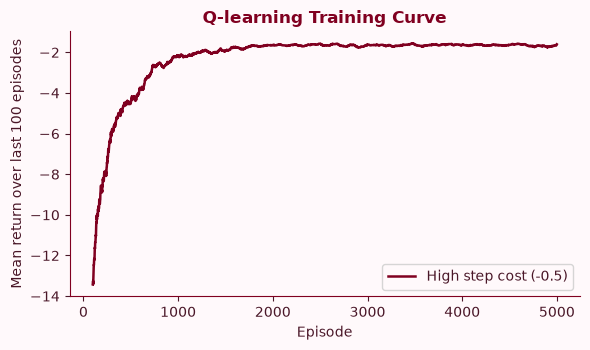

In [40]:
# 4. Plot training performance

window = 100

moving_new = np.convolve(
    training_returns_new,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(6, 3.6))

plt.plot(
    np.arange(window - 1, len(training_returns_new)),
    moving_new,
    color="#800020",
    linewidth=1.8,
    label="High step cost (-0.5)"
)

plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")

plt.title(
    "Q-learning Training Curve",
    color="#800020",
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

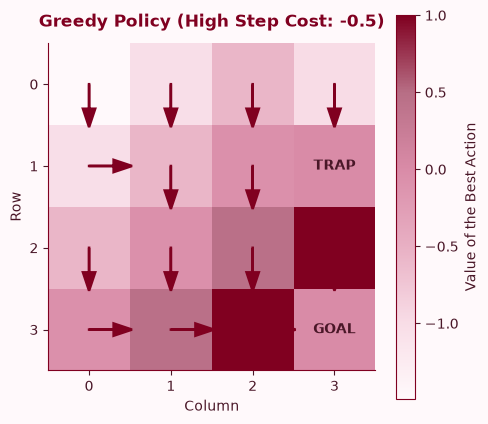

In [41]:
# 5. Display the learned policy

plot_policy(
    Q_new,
    "Greedy Policy (High Step Cost: -0.5)"
)

In [42]:
# Verify the greedy policy from START

state = START
total_reward = 0
route = [state]

for _ in range(100):
    action = int(np.argmax(Q_new[state]))

    state, reward, done = step_high_cost(state, action)

    total_reward += reward
    route.append(state)

    if done:
        break

print("Learned route:", route)
print("Number of moves:", len(route) - 1)
print("Total reward:", total_reward)
print("Reached goal:", state == GOAL)

Learned route: [(0, 0), (1, 0), (1, 1), (2, 1), (3, 1), (3, 2), (3, 3)]
Number of moves: 6
Total reward: -1.5
Reached goal: True
